In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df = pd.read_csv("dataset.csv")
df["release_date"] = pd.to_datetime(df["release_date"], errors="coerce")
df = df.drop(df.columns[0], axis=1)
df.head()

,title,console,genre,publisher,developer,critic_score,total_sales,na_sales,jp_sales,pal_sales,other_sales,release_date,last_update
0,Grand Theft Auto V,PS3,Action,Rockstar Games,Rockstar North,9.4,20.32,6.37,0.99,9.85,3.12,2013-09-17,NaN
1,Grand Theft Auto V,PS4,Action,Rockstar Games,Rockstar North,9.7,19.39,6.06,0.60,9.71,3.02,2014-11-18,2018-01-03
2,Grand Theft Auto: Vice City,PS2,Action,Rockstar Games,Rockstar North,9.6,16.15,8.41,0.47,5.49,1.78,2002-10-28,NaN
3,Grand Theft Auto V,X360,Action,Rockstar Games,Rockstar North,NaN,15.86,9.06,0.06,5.33,1.42,2013-09-17,NaN
4,Call of Duty: Black Ops 3,PS4,Shooter,Activision,Treyarch,8.1,15.09,6.18,0.41,6.05,2.44,2015-11-06,2018-01-14


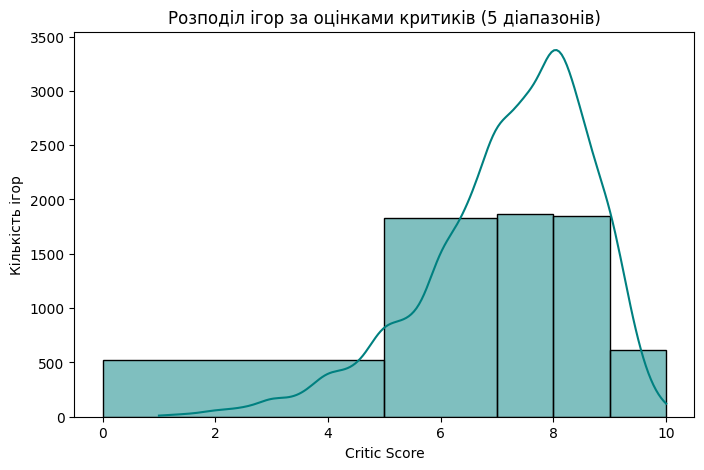

In [3]:
plt.figure(figsize=(8,5))
bins = [0, 5, 7, 8, 9, 10]
sns.histplot(df["critic_score"], bins=bins, kde=True, color="teal")
plt.title("Розподіл ігор за оцінками критиків (5 діапазонів)")
plt.xlabel("Critic Score")
plt.ylabel("Кількість ігор")
plt.show()

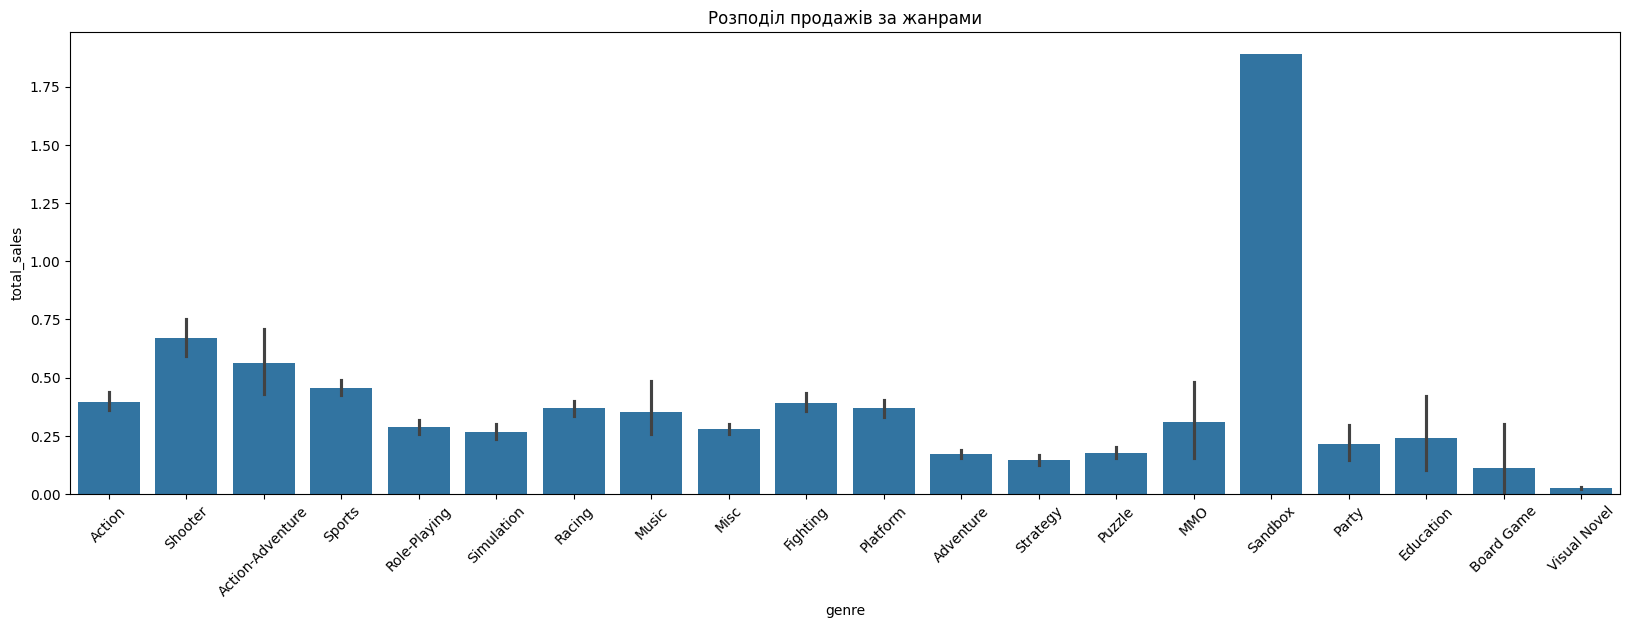

In [4]:
#total_sales за жанром
plt.figure(figsize=(20,6))
sns.barplot(data=df, x="genre", y="total_sales")
plt.title("Розподіл продажів за жанрами")
plt.xticks(rotation=45)
plt.show()

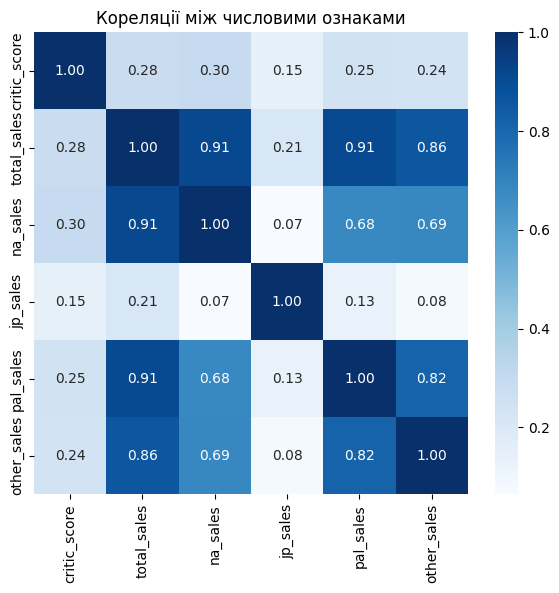

In [5]:
#heatmap
plt.figure(figsize=(7,6))
corr = df[["critic_score","total_sales","na_sales","jp_sales","pal_sales","other_sales"]].corr()
sns.heatmap(corr, annot=True, cmap="Blues", fmt=".2f")
plt.title("Кореляції між числовими ознаками")
plt.show()

C:\Users\Mykola\AppData\Local\Temp\ipykernel_22692\1409646072.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=top_titles, x="total_sales", y="title", palette="viridis")


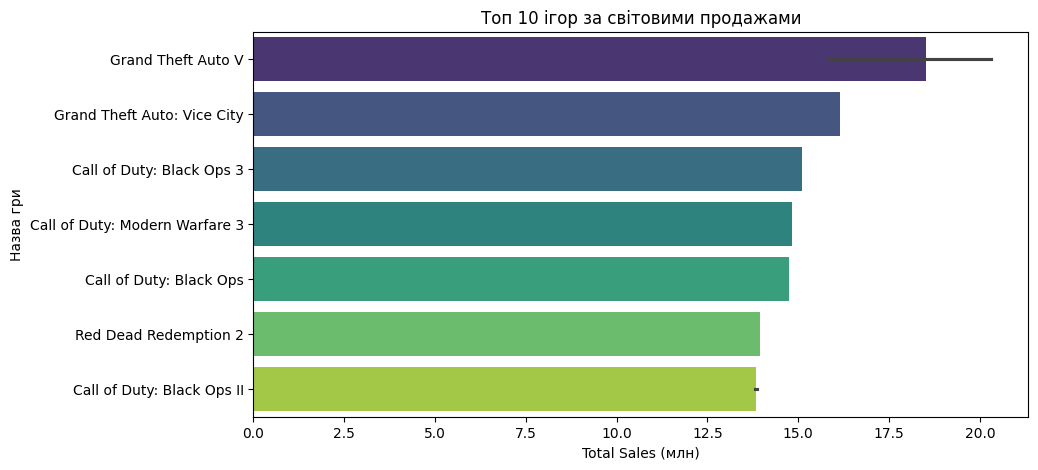

In [6]:
# Топ 10 ігор за світовими продажами
top_titles = df.nlargest(10, "total_sales")[["title", "total_sales"]]
plt.figure(figsize=(10,5))
sns.barplot(data=top_titles, x="total_sales", y="title", palette="viridis")
plt.title("Топ 10 ігор за світовими продажами")
plt.xlabel("Total Sales (млн)")
plt.ylabel("Назва гри")
plt.show()

C:\Users\Mykola\AppData\Local\Temp\ipykernel_22692\4175303204.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=antitop_titles, x="total_sales", y="title", palette="viridis")


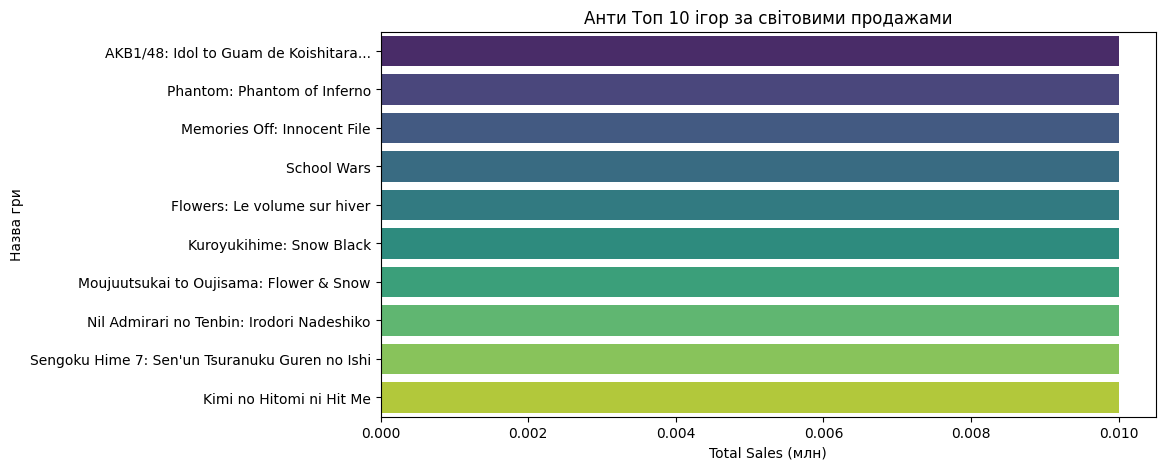

,title,total_sales
16204,AKB1/48: Idol to Guam de Koishitara...,0.01
16205,Phantom: Phantom of Inferno,0.01
16206,Memories Off: Innocent File,0.01
16207,School Wars,0.01
16208,Flowers: Le volume sur hiver,0.01
16209,Kuroyukihime: Snow Black,0.01
16210,Moujuutsukai to Oujisama: Flower & Snow,0.01
16211,Nil Admirari no Tenbin: Irodori Nadeshiko,0.01
16212,Sengoku Hime 7: Sen'un Tsuranuku Guren no Ishi,0.01
16213,Kimi no Hitomi ni Hit Me,0.01


In [7]:
# АНТИ Топ 10 ігор за світовими продажами
df_non_zero_sales = df[df["total_sales"] > 0]
antitop_titles = df_non_zero_sales.nsmallest(10, "total_sales")[["title", "total_sales"]]
#antitop_titles = df.nsmallest(10, "total_sales")[["title", "total_sales"]]
plt.figure(figsize=(10,5))
sns.barplot(data=antitop_titles, x="total_sales", y="title", palette="viridis")
plt.title("Анти Топ 10 ігор за світовими продажами")
plt.xlabel("Total Sales (млн)")
plt.ylabel("Назва гри")
plt.show()
antitop_titles

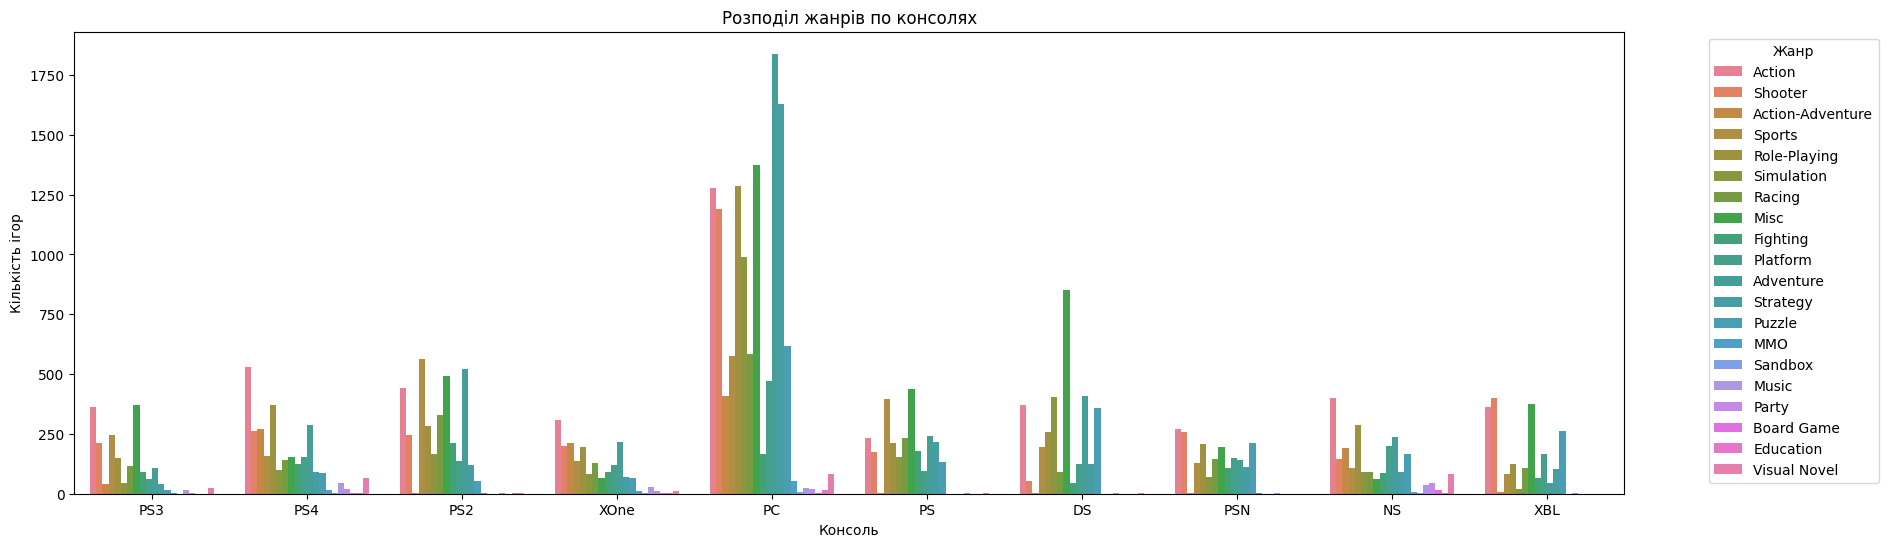

In [8]:
# Консолі та жанри
plt.figure(figsize=(20,6))
top_consoles = df["console"].value_counts().nlargest(10).index
sns.countplot(data=df[df["console"].isin(top_consoles)], x="console", hue="genre")
plt.title("Розподіл жанрів по консолях")
plt.xlabel("Консоль")
plt.ylabel("Кількість ігор")
plt.legend(title="Жанр", bbox_to_anchor=(1.05, 1), loc="upper left")
plt.show()

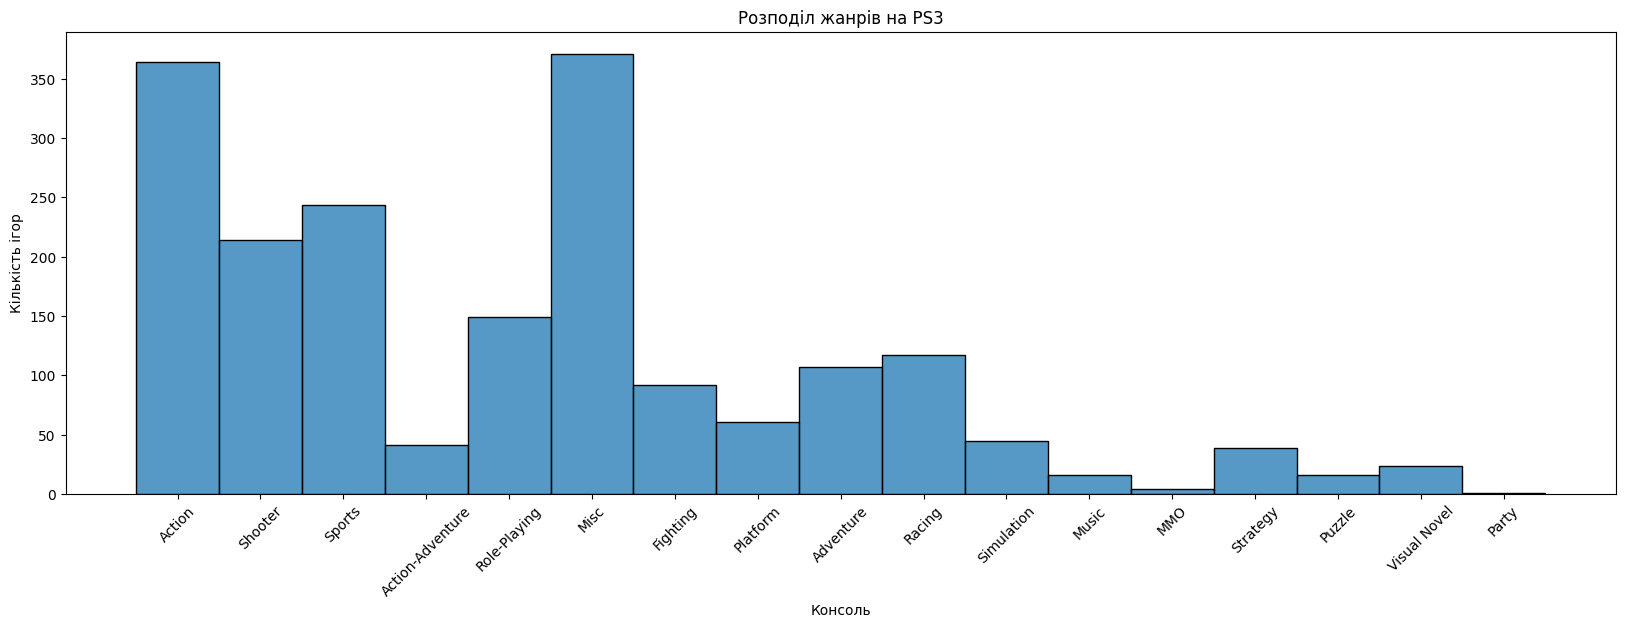

In [9]:
target_console = "PS3"
df_filtered = df[df["console"] == target_console]

plt.figure(figsize=(20,6))
top_consoles = df["console"].value_counts().nlargest(10).index
sns.histplot(df_filtered['genre'])
plt.title("Розподіл жанрів на "+target_console)
plt.xlabel("Консоль")
plt.ylabel("Кількість ігор")
plt.xticks(rotation=45)
plt.show()

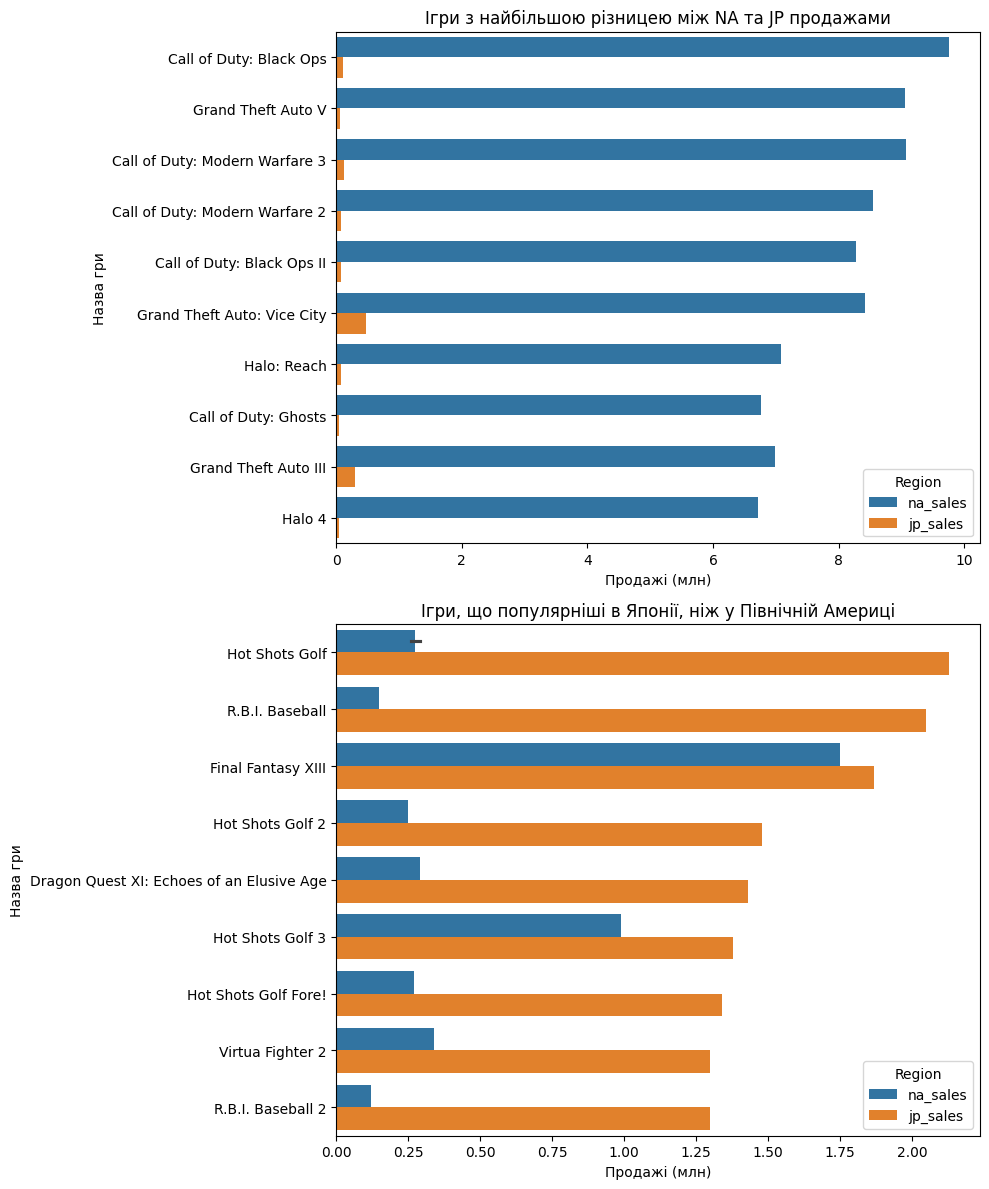

In [10]:
#Порівняння продажів у Північній Америці та Японії
df["region_diff"] = (df["na_sales"] - df["jp_sales"]).abs()
regional_diff = df.nlargest(10, "region_diff")[["title", "na_sales", "jp_sales"]]

regional_diff_melted = regional_diff.melt(id_vars="title", value_vars=["na_sales", "jp_sales"],
                                          var_name="Region", value_name="Sales")


jp_favored = df[df["jp_sales"] > df["na_sales"]].nlargest(10, "jp_sales")[["title", "na_sales", "jp_sales"]]
jp_favored_melted = jp_favored.melt(
    id_vars="title",
    value_vars=["na_sales", "jp_sales"],
    var_name="Region",
    value_name="Sales"
)
fig, axes = plt.subplots(2, 1, figsize=(10, 12))
axes[0].set_title("Ігри з найбільшою різницею між NA та JP продажами")
axes[0].set_xlabel("Продажі (млн)")
axes[0].set_ylabel("Назва гри")


axes[1].set_title("Ігри, що популярніші в Японії, ніж у Північній Америці")
axes[1].set_xlabel("Продажі (млн)")
axes[1].set_ylabel("Назва гри")

sns.barplot(data=jp_favored_melted,x="Sales", y="title", hue="Region", ax=axes[1])
sns.barplot(data=regional_diff_melted,x="Sales", y="title", hue="Region", ax=axes[0])
plt.tight_layout()
plt.show()

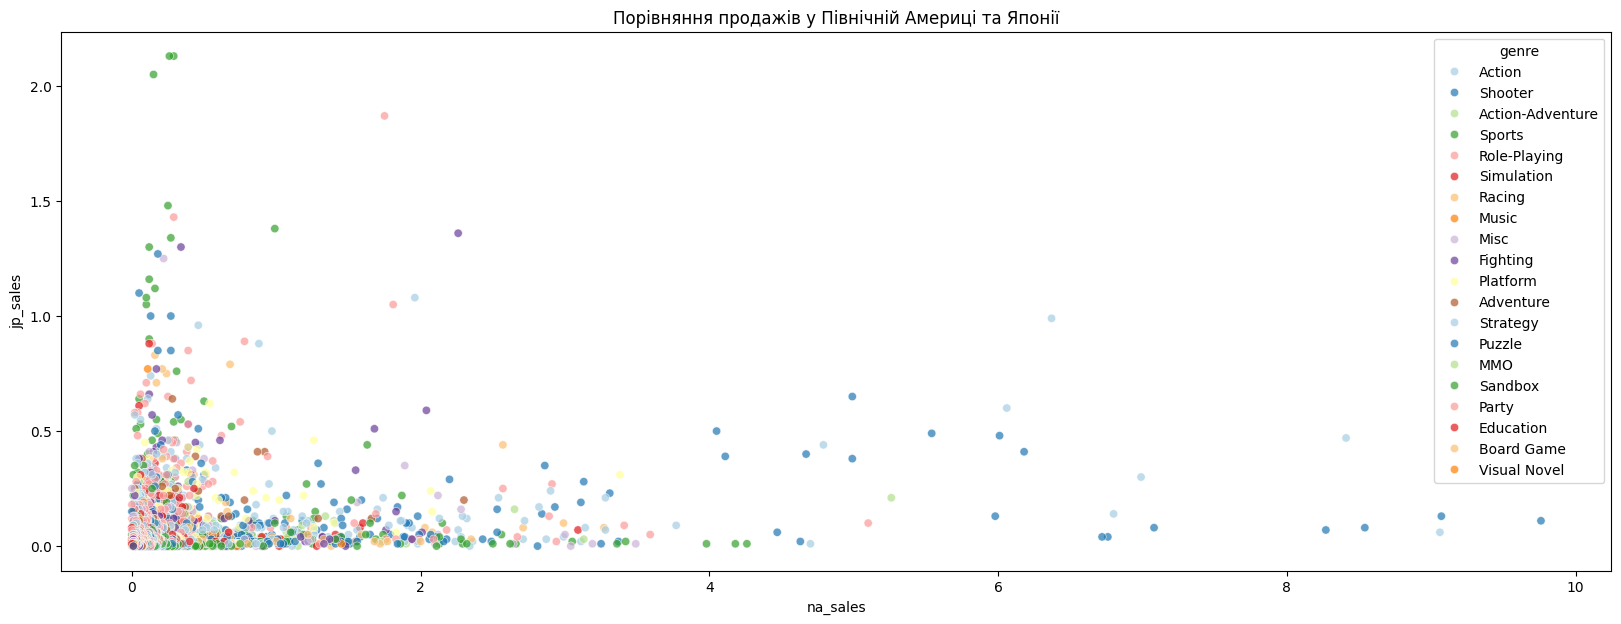

In [11]:
#na_sales проти jp_sales
plt.figure(figsize=(20,7))
sns.scatterplot(data=df, x="na_sales", y="jp_sales", hue="genre", alpha=0.7, palette="Paired")
plt.title("Порівняння продажів у Північній Америці та Японії")
plt.show()

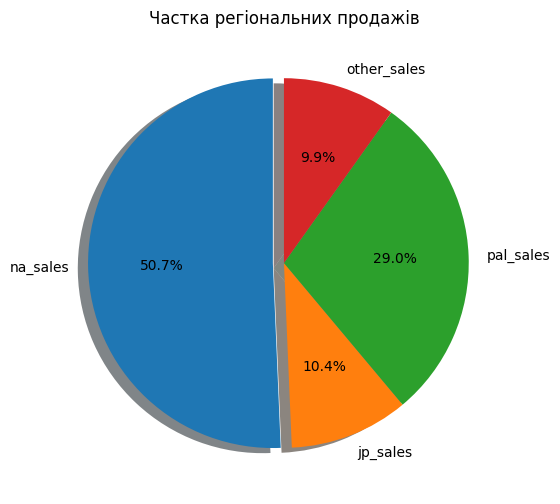

In [12]:
#Частка продажів по регіонах
region_sums = df[["na_sales","jp_sales","pal_sales","other_sales"]].sum()
plt.figure(figsize=(6,6))
plt.pie(region_sums, labels=region_sums.index, autopct="%1.1f%%", startangle=90, shadow={'ox': -0.04, 'edgecolor': 'none', 'shade': 0.9}, explode=(0.06,0,0,0))
plt.title("Частка регіональних продажів")
plt.show()

C:\Users\Mykola\AppData\Local\Temp\ipykernel_22692\3122816521.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(data=sales_melted, x="region", y="sales", scale="width", inner="quartile", palette="muted")
C:\Users\Mykola\AppData\Local\Temp\ipykernel_22692\3122816521.py:5: FutureWarning: 

The `scale` parameter has been renamed and will be removed in v0.15.0. Pass `density_norm='width'` for the same effect.
  sns.violinplot(data=sales_melted, x="region", y="sales", scale="width", inner="quartile", palette="muted")


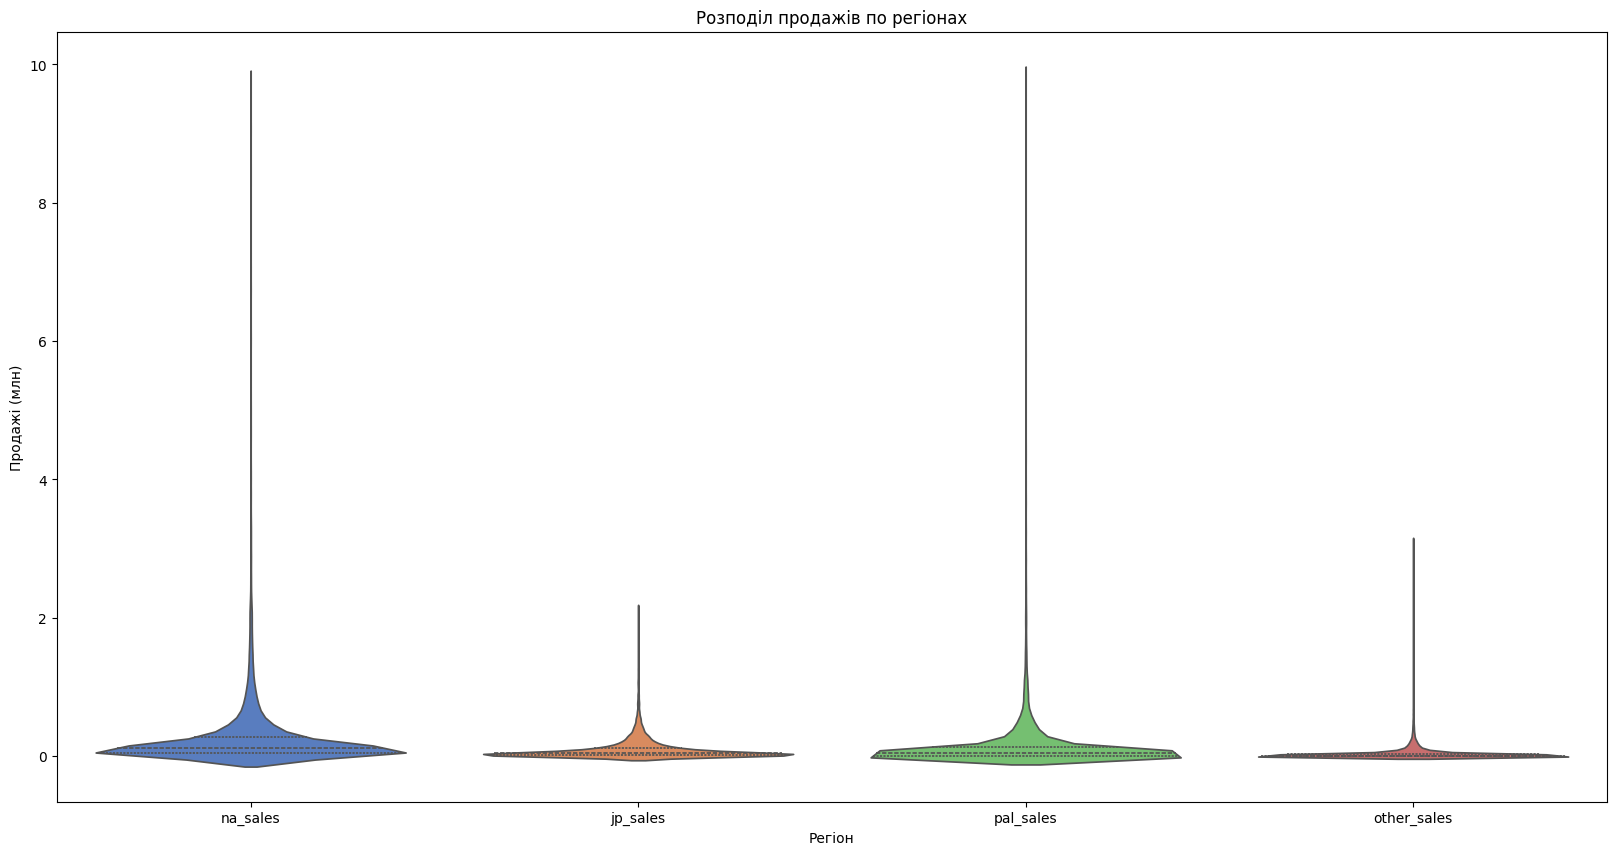

In [13]:
sales_melted = df.melt(value_vars=["na_sales", "jp_sales", "pal_sales", "other_sales"],
                       var_name="region", value_name="sales")

plt.figure(figsize=(20,10))
sns.violinplot(data=sales_melted, x="region", y="sales", scale="width", inner="quartile", palette="muted")
plt.title("Розподіл продажів по регіонах")
plt.xlabel("Регіон")
plt.ylabel("Продажі (млн)")
plt.show()

C:\Users\Mykola\AppData\Local\Temp\ipykernel_22692\880656007.py:7: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  avg_scores = df_trend.groupby("sales_range")["critic_score"].mean().reset_index()


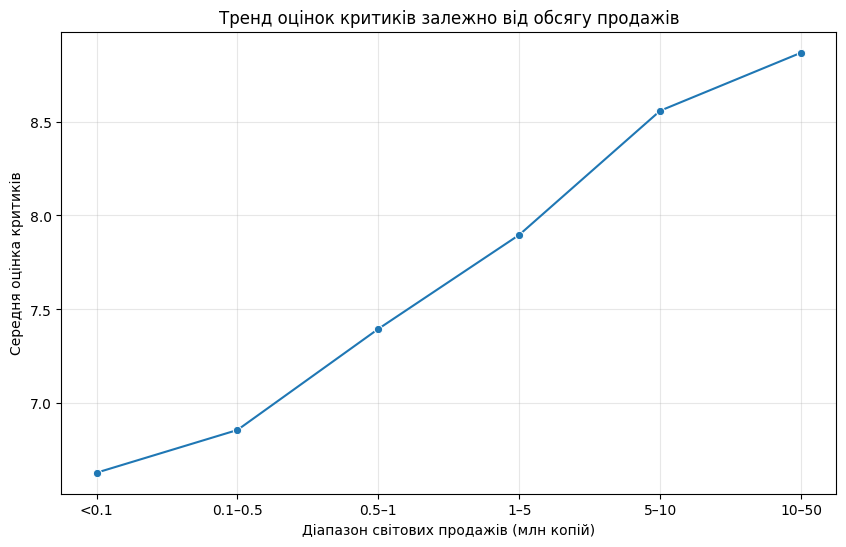

In [14]:
df_trend = df.copy()

bins = [0, 0.1, 0.5, 1, 5, 10, 50, 100]
labels = ["<0.1", "0.1–0.5", "0.5–1", "1–5", "5–10", "10–50", ">50"]
df_trend["sales_range"] = pd.cut(df_trend["total_sales"], bins=bins, labels=labels, include_lowest=True)

avg_scores = df_trend.groupby("sales_range")["critic_score"].mean().reset_index()

plt.figure(figsize=(10,6))
sns.lineplot(data=avg_scores, x="sales_range", y="critic_score", marker = "o")
plt.title("Тренд оцінок критиків залежно від обсягу продажів")
plt.xlabel("Діапазон світових продажів (млн копій)")
plt.ylabel("Середня оцінка критиків")
plt.grid(True, alpha=0.3)
plt.show()